In [3]:
#Testing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("EDA environment ready!")
print("Pandas version:", pd.__version__)

EDA environment ready!
Pandas version: 3.1.1


# EGT309 — Predictive Maintenance EDA
## 1. Dataset Overview

### Objective:
The objective of this EDA analysis is to understand the machine sensor dataset and investigate factors associated with maintenance requirements.

The dataset contains readings collected from 50 manufacturing machines.

Our target variable is `maintenance_required`:
- 0: Maintenance not required
- 1: Maintenance required

In [4]:
# Load the machine sensor dataset
df = pd.read_csv("data/proj_machine_readings.csv")

# Display the first five rows
df.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


In [5]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Number of unique machines
print("Number of machines:", df["machine_id"].nunique())

# Display column names
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (100000, 13)
Number of machines: 50

Columns:
['timestamp', 'machine_id', 'temperature', 'vibration', 'humidity', 'pressure', 'energy_consumption', 'machine_status', 'anomaly_flag', 'predicted_remaining_life', 'failure_type', 'downtime_risk', 'maintenance_required']


## 2. Data Quality Assessment

### Objective:
To identify missing values, duplicate records, and data type issues that could affect the reliability of our machine learning models.

### Methods used:
- Inspecting column data types.
- Count missing values in each column.
- Checking for duplicate records.
- Identifying potential inconsistencies in sensor readings.

In [6]:
# Check data types and missing values
#  Display dataset information
df.info()

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Combine results into a table
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000 non-null  int64  
 10  failure_type              100000 non-null  str    
 11  downtime_risk             100000 non-null  float64
 12  maintenance_required      100000 non-null  int64  
dtypes: float64(6), int64(5), str(2)
memory usage: 9.9 MB


,Missing Count,Missing Percentage
timestamp,0,0.0
machine_id,0,0.0
temperature,14000,14.0
vibration,0,0.0
humidity,0,0.0
pressure,0,0.0
energy_consumption,0,0.0
machine_status,0,0.0
anomaly_flag,0,0.0
predicted_remaining_life,0,0.0


In [7]:
#Checking for duplicates

# Count completely identical rows
duplicate_count = df.duplicated().sum()

# Check duplicate readings for the same machine and timestamp
duplicate_machine_time = df.duplicated(
    subset=["machine_id", "timestamp"]
).sum()

print("Fully duplicated rows:", duplicate_count)
print("Duplicate machine-timestamp records:", duplicate_machine_time)

Fully duplicated rows: 0
Duplicate machine-timestamp records: 0


### Data Quality Findings

The dataset given contains 100,000 observations across 50 machines.

Missing-value analysis identified 14,000 missing values (14%) in the `temperature` column. All other columns have complete data.

Duplicate analysis identified zero fully duplicated records and zero duplicate machine-timestamp combinations.

**Implications:**

- Temperature missing values will require further investigation and appropriate handling before model training.
- No removal of duplicates is currently necessary.
- The original dataset will be preserved during exploratory analysis.
- Imputation methods will be selected based on the temperature distribution and missingness patterns.

In [8]:
# Summary statistics for temperature
print(df["temperature"].describe())

# Check missing temperatures by machine
missing_by_machine = (
    df.groupby("machine_id")["temperature"]
    .apply(lambda x: x.isna().mean() * 100)
    .sort_values(ascending=False)
)

print("\nMissing temperature percentage by machine:")
display(missing_by_machine)

count    86000.000000
mean        75.034410
std         10.036257
min         35.550000
25%         68.280000
50%         75.090000
75%         81.780000
max        121.940000
Name: temperature, dtype: float64

Missing temperature percentage by machine:


machine_id
25    15.715716
3     15.692154
6     15.253361
2     14.894659
22    14.820286
20    14.720812
44    14.703019
28    14.697266
37    14.409369
7     14.402036
10    14.391691
38    14.382896
13    14.362745
42    14.314017
49    14.307692
26    14.278776
16    14.228856
24    14.213710
39    14.199699
12    14.168798
34    14.168378
43    14.165792
48    14.091351
47    14.042979
36    14.004796
17    13.973799
46    13.964435
45    13.942308
1     13.935282
35    13.904861
33    13.854806
27    13.847726
14    13.807316
18    13.786312
29    13.698630
21    13.693957
5     13.656388
40    13.643178
15    13.616182
32    13.490891
8     13.421454
11    13.326499
41    13.263785
4     13.173653
30    13.162970
50    13.075314
31    12.984997
19    12.824351
9     12.757408
23    12.571702
Name: temperature, dtype: float64

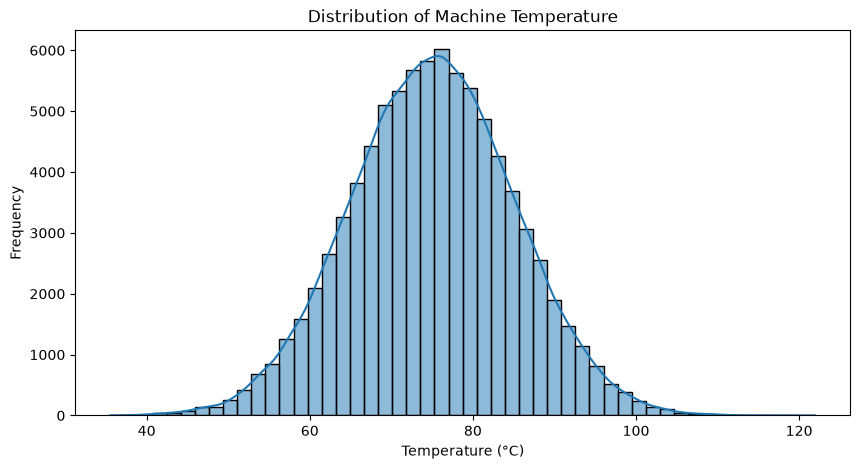

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="temperature",
    bins=50,
    kde=True
)

plt.title("Distribution of Machine Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.show()

### Temperature Distribution — Findings

1) The temperature column contains 86,000 valid observations and 14,000 missing values (14%). 
2) The observed temperature readings are approximately normally distributed, with a mean of 75.03°C, median of 75.09°C and standard deviation of 10.04°C.
3) The similarity between the mean and median suggests that the distribution has little overall skewness.
4) Missing temperature values are distributed across multiple machines, with no obvious concentration in the displayed machine-level results.

**Implications for preprocessing:**

Median imputation is a potential approach because it is robust to extreme values. However, additional analysis is needed to determine whether missingness is associated with maintenance requirements or individual machines.

The original temperature values will remain unchanged during EDA. Imputation will be performed within the machine learning preprocessing pipeline.

In [10]:
# Compare missing temperature rates by maintenance status
missing_by_maintenance = (
    df.assign(temperature_missing=df["temperature"].isna())
    .groupby("maintenance_required")["temperature_missing"]
    .agg(["sum", "count", "mean"])
)

missing_by_maintenance["missing_percentage"] = (
    missing_by_maintenance["mean"] * 100
)

display(missing_by_maintenance)

,sum,count,mean,missing_percentage
maintenance_required,,,,
0,11287,80303,0.140555,14.055515
1,2713,19697,0.137737,13.773671


## 3. Sensor Readings Analysis

### Objective:
To investigate the distributions, ranges, and potential outliers of the machine sensor readings.

This analysis will help identify unusual values and determine whether additional preprocessing is required.

In [11]:
#Show values: (ount, mean, standard deviation, minimum, quartiles and maximum for all five sensors.)

sensor_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption"
]

# Generate descriptive statistics
sensor_summary = df[sensor_columns].describe().T

display(sensor_summary)

,count,mean,std,min,25%,50%,75%,max
temperature,86000.0,75.034410,10.036257,35.55,68.28,75.090,81.78,121.94
vibration,100000.0,43.324232,29.134306,-106.98,37.22,48.635,59.25,113.80
humidity,100000.0,54.995401,14.437960,30.00,42.52,54.980,67.50,80.00
pressure,100000.0,3.000405,1.152399,1.00,2.00,3.010,4.00,5.00
energy_consumption,100000.0,2.747064,1.297865,0.50,1.63,2.740,3.87,5.00


### Sensor Readings — Descriptive Statistics Findings

Descriptive statistics were generated for temperature, vibration, humidity, pressure and energy consumption to identify unusual values and potential data quality issues.

Temperature has a mean of 75.03°C, with readings ranging from 35.55°C to 121.94°C. The relatively high maximum temperature warrants further investigation.

Vibration has a mean of 43.32 mm/s, with readings ranging from -106.98 mm/s to 113.80 mm/s. Negative values are potentially invalid if vibration represents magnitude rather than signed velocity.

Humidity, pressure and energy consumption fall within physically plausible ranges, although machine-specific operating limits are unknown.

**Implications:** Further investigation is required to determine the frequency and distribution of negative vibration readings before selecting a cleaning method. No sensor values will be removed or modified at this stage.

In [12]:
# Count negative values

# Identify negative vibration readings
negative_vibration = df["vibration"] < 0

# Count negative readings
negative_count = negative_vibration.sum()

# Calculate percentage
negative_percentage = negative_count / len(df) * 100

print("Negative vibration readings:", negative_count)
print(f"Percentage of dataset: {negative_percentage:.2f}%")

Negative vibration readings: 6703
Percentage of dataset: 6.70%


In [13]:
# Compare negative vibration readings by maintenance status
vibration_maintenance = pd.crosstab(
    df["maintenance_required"],
    df["vibration"] < 0,
    margins=True
)

display(vibration_maintenance)

vibration,False,True,All
maintenance_required,,,
0,74913,5390,80303
1,18384,1313,19697
All,93297,6703,100000


### Negative Vibration Analysis — Findings

A total of 6,703 observations (6.70%) contain negative vibration readings.

Among observations where maintenance is not required, 6.71% have negative vibration values. For observations requiring maintenance, the corresponding percentage is 6.67%.

The difference of approximately 0.04 percentage points suggests that negative vibration readings are not strongly associated with the maintenance target.

However, this does not establish whether vibration magnitude is predictive of maintenance requirements.

**Implications:** Negative vibration values will be retained during EDA until their measurement interpretation is clarified. Further analysis will examine the overall vibration distribution and its relationship with maintenance requirements.

### Investigation of Negative Vibration Readings

**Objective:** Investigate whether negative vibration readings
occur randomly or follow a systematic timestamp pattern.

**Method:** Examine the timestamps of negative vibration
readings and compare their frequencies across minute values.

**Importance:** Identifying systematic measurement anomalies
helps determine whether data correction is appropriate
before model training.

Total negative readings: 6703
Quarter-hour readings: 6667
Negative readings at quarter-hour timestamps: 6667
Negative readings at other timestamps: 36


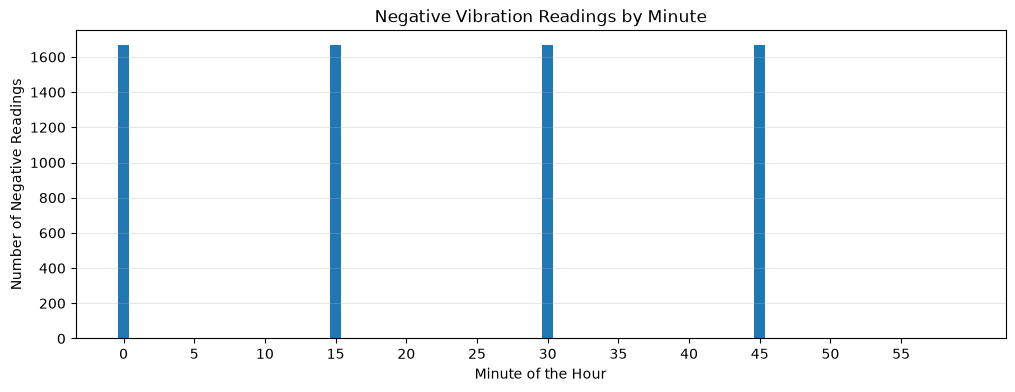

In [14]:
# Investigate negative vibration readings by timestamp

# Ensure timestamp is in datetime format
timestamps = pd.to_datetime(df["timestamp"])

# Identify negative vibration readings
negative = df["vibration"] < 0

# Extract minute of each timestamp
minute = timestamps.dt.minute

# Identify quarter-hour timestamps
quarter_hour = minute % 15 == 0

# Summarize the findings
print("Total negative readings:", negative.sum())

print(
    "Quarter-hour readings:",
    quarter_hour.sum()
)

print(
    "Negative readings at quarter-hour timestamps:",
    (negative & quarter_hour).sum()
)

print(
    "Negative readings at other timestamps:",
    (negative & ~quarter_hour).sum()
)

# Count negative readings by minute
negative_by_minute = negative.groupby(minute).sum()

plt.figure(figsize=(12, 4))

plt.bar(
    negative_by_minute.index,
    negative_by_minute.values
)

plt.xlabel("Minute of the Hour")
plt.ylabel("Number of Negative Readings")
plt.title("Negative Vibration Readings by Minute")
plt.xticks(range(0, 60, 5))
plt.grid(axis="y", alpha=0.3)

plt.show()

### Negative Vibration Magnitude Validation

**Objective:** Determine whether negative vibration readings
have magnitudes comparable to positive vibration readings.

**Method:** Compare descriptive statistics of positive readings
with the absolute magnitudes of negative readings.

**Importance:** This helps assess whether a sign correction
is reasonable before model development.

In [15]:
# Compare positive and negative vibration magnitudes

positive_vibration = df.loc[
    df["vibration"] >= 0, "vibration"
]

quarter_hour_negative = df.loc[
    negative & quarter_hour, "vibration"
].abs()

other_negative = df.loc[
    negative & ~quarter_hour, "vibration"
].abs()

comparison = pd.DataFrame({
    "Positive Readings": positive_vibration.describe(),
    "Quarter-Hour Negative (Absolute)": quarter_hour_negative.describe(),
    "Other Negative (Absolute)": other_negative.describe()
})

display(comparison.round(2))

,Positive Readings,Quarter-Hour Negative (Absolute),Other Negative (Absolute)
count,93297.00,6667.00,36.00
mean,50.02,50.16,4.57
std,14.95,14.91,4.28
min,0.10,2.81,0.02
25%,39.96,40.23,1.59
50%,49.96,50.14,3.15
75%,60.11,60.10,6.15
max,113.80,106.98,17.09


### Negative Vibration Magnitude Validation — Findings

A total of 6,703 negative vibration readings were identified.

Of these, 6,667 occurred at quarter-hour timestamps (00, 15, 30 and 45 minutes). Every observation recorded at these timestamps had a negative vibration value.

The absolute magnitudes of these quarter-hour readings closely matched the distribution of positive vibration readings:

- Positive readings: Mean = 50.02, Median = 49.96, Standard Deviation = 14.95.
- Quarter-hour negative readings (absolute): Mean = 50.16, Median = 50.14, Standard Deviation = 14.91.

This provides strong evidence of a systematic sign inversion affecting quarter-hour vibration measurements.

The remaining 36 negative readings had substantially smaller absolute magnitudes, with a mean of 4.57 and median of 3.15, suggesting a potentially different underlying cause.

**Implications:**

A timestamp-based sign correction is a reasonable preprocessing approach for the 6,667 quarter-hour readings, subject to confirmation of the measurement convention.

The remaining 36 negative readings should be investigated separately rather than automatically corrected.

The original dataset will be preserved, with any corrections applied to a separate working copy.

In [16]:
# Create a separate working copy
df_clean = df.copy()

# Convert timestamp for checking quarter-hour intervals
timestamp_clean = pd.to_datetime(df_clean["timestamp"])

# Identify quarter-hour readings with negative vibration
sign_inversion_mask = (
    (timestamp_clean.dt.minute % 15 == 0) &
    (df_clean["vibration"] < 0)
)

# Correct only the identified sign-inverted readings
df_clean.loc[sign_inversion_mask, "vibration"] *= -1

# Verify correction
print("Readings corrected:", sign_inversion_mask.sum())

print(
    "Remaining negative readings:",
    (df_clean["vibration"] < 0).sum()
)

print("\nOriginal vibration statistics:")
display(df["vibration"].describe().round(2))

print("\nCorrected vibration statistics:")
display(df_clean["vibration"].describe().round(2))

Readings corrected: 6667
Remaining negative readings: 36

Original vibration statistics:


count    100000.00
mean         43.32
std          29.13
min        -106.98
25%          37.22
50%          48.64
75%          59.25
max         113.80
Name: vibration, dtype: float64


Corrected vibration statistics:


count    100000.00
mean         50.01
std          14.98
min         -17.09
25%          39.97
50%          49.96
75%          60.10
max         113.80
Name: vibration, dtype: float64

### Vibration Distribution Before and After Correction

**Objective:** Evaluate how the timestamp-based sign correction
changes the distribution of vibration readings.

**Method:** Compare histograms of original and corrected
vibration measurements.

**Importance:** This helps assess whether the correction
removes the systematic negative cluster while preserving
the overall sensor distribution.

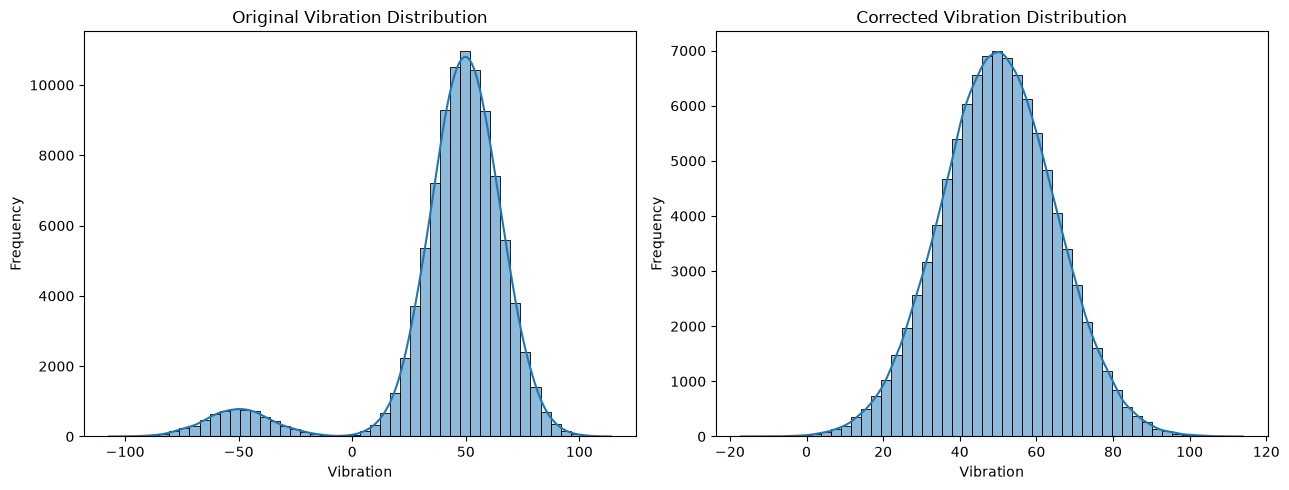

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Original vibration distribution
sns.histplot(
    df["vibration"],
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original Vibration Distribution")
axes[0].set_xlabel("Vibration")
axes[0].set_ylabel("Frequency")

# Corrected vibration distribution
sns.histplot(
    df_clean["vibration"],
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Corrected Vibration Distribution")
axes[1].set_xlabel("Vibration")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Vibration Distribution Correction — Findings

The original vibration distribution was bimodal, with a dominant positive cluster around 50 and a secondary negative cluster around -50.

After applying a timestamp-based sign correction to 6,667 quarter-hour readings, the secondary negative cluster disappeared.

The mean vibration increased from 43.32 to 50.01, while the standard deviation decreased from 29.13 to 14.98.

The corrected distribution is approximately bell-shaped, with 36 negative readings remaining.

**Implications:**

The results provide additional evidence supporting a systematic sign inversion in the quarter-hour vibration measurements.

The correction produces a more consistent vibration distribution without removing any observations.

However, the correction remains an assumption based on observed patterns and should be documented in the preprocessing pipeline.

### Effect of Vibration Correction on Maintenance Correlation

**Objective:** Determine whether correcting suspected sign-inverted
vibration readings changes their relationship with maintenance requirements.

**Method:** Calculate and compare Pearson correlations before and
after vibration correction.

**Importance:** This helps evaluate whether systematic measurement
errors were affecting the apparent predictive usefulness of vibration.

In [18]:
# Compare vibration correlations before and after correction

original_corr = df[
    ["vibration", "maintenance_required"]
].corr().loc["vibration", "maintenance_required"]

corrected_corr = df_clean[
    ["vibration", "maintenance_required"]
].corr().loc["vibration", "maintenance_required"]

print(f"Original vibration correlation: {original_corr:.4f}")
print(f"Corrected vibration correlation: {corrected_corr:.4f}")
print(f"Correlation change: {corrected_corr - original_corr:+.4f}")

Original vibration correlation: 0.0513
Corrected vibration correlation: 0.1131
Correlation change: +0.0618


### Effect of Vibration Correction on Maintenance Correlation — Findings

The Pearson correlation between vibration and `maintenance_required` increased from 0.0513 to 0.1131 after correcting the 6,667 suspected sign-inverted readings.

This represents an absolute increase of 0.0618 in the correlation coefficient.

**Interpretation:**

The increase suggests that the systematic sign inversion was obscuring part of the positive linear relationship between vibration and maintenance requirements.

However, the corrected correlation remains weak, indicating that vibration alone is unlikely to provide reliable maintenance classification.

Temperature remains the strongest individual raw sensor feature based on Pearson correlation.

**Implications:**

The timestamp-based correction improves the consistency of vibration measurements and increases their observed linear association with maintenance requirements.

The correction should be included as a documented preprocessing assumption and evaluated through model performance comparisons.

### Maintenance Target Rule Investigation

**Objective:** Determine whether maintenance_required can be
reproduced using machine_status, anomaly_flag and
predicted_remaining_life.

**Method:** Construct a rule-based maintenance prediction
and compare it against the recorded target labels.

**Importance:** An exact relationship may indicate that
these derived variables directly encode the target,
creating a significant risk of target leakage.

In [19]:
# Reconstruct maintenance labels using derived features
rule_prediction = (
    (df["machine_status"] == 2) |
    (df["anomaly_flag"] == 1) |
    (df["predicted_remaining_life"] < 20)
).astype(int)

# Compare reconstructed labels with actual labels
matches = (
    rule_prediction == df["maintenance_required"]
)

print("Total observations:", len(df))
print("Matching labels:", matches.sum())
print("Mismatching labels:", (~matches).sum())
print(f"Agreement: {matches.mean() * 100:.2f}%")

# Show confusion matrix
display(
    pd.crosstab(
        df["maintenance_required"],
        rule_prediction,
        rownames=["Actual"],
        colnames=["Rule Prediction"]
    )
)

Total observations: 100000
Matching labels: 100000
Mismatching labels: 0
Agreement: 100.00%


Rule Prediction,0,1
Actual,,
0,80303,0
1,0,19697


### Maintenance Target Rule Investigation — Findings

A rule-based reconstruction of `maintenance_required` was performed using three derived features: `machine_status`, `anomaly_flag` and `predicted_remaining_life`.

The rule assigned maintenance as required whenever at least one of the following conditions was satisfied:

- Machine status equals 2.
- Anomaly flag equals 1.
- Predicted remaining life is below 20.

The reconstructed labels matched all 100,000 recorded maintenance labels, achieving 100% agreement with zero mismatches.

**Interpretation:**

The exact agreement provides strong evidence that these derived variables encode the maintenance target.

Although the original label-generation mechanism cannot be confirmed from this analysis alone, the relationship presents a substantial risk of target leakage.

**Implications:**

These three derived features should be excluded from the primary predictive model to avoid learning an existing deterministic relationship rather than identifying maintenance requirements from sensor measurements.

The initial model will use raw sensor features, with preprocessing performed using training data only.

### Anomaly Flag and Sensor Threshold Analysis

**Objective:** Investigate whether anomaly flags are associated
with unusually high temperature or vibration readings.

**Method:** Compare sensor distributions for observations
with and without anomaly flags.

**Importance:** Understanding the relationship between anomaly
flags and raw sensors helps assess whether the maintenance
target can be predicted without using derived indicators.

In [20]:
# Compare sensor statistics by anomaly flag
anomaly_summary = df_clean.groupby(
    "anomaly_flag"
)[["temperature", "vibration"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(anomaly_summary.round(2))

# Examine extreme readings in anomalous observations
print("\nTemperature percentiles by anomaly flag:")
display(
    df_clean.groupby("anomaly_flag")["temperature"]
    .quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    .unstack()
    .round(2)
)

print("\nVibration percentiles by anomaly flag:")
display(
    df_clean.groupby("anomaly_flag")["vibration"]
    .quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    .unstack()
    .round(2)
)

temperature                                     vibration         \
                   count   mean median    std    min     max     count   mean   
anomaly_flag                                                                    
0                  78312  73.63  74.22   8.81  35.55   90.00     91084  49.18   
1                   7688  89.37  92.05  10.49  41.71  121.94      8916  58.51   

                                          
             median    std    min    max  
anomaly_flag                              
0             49.54  14.10 -17.09   80.0  
1             56.06  20.22  -6.12  113.8


Temperature percentiles by anomaly flag:


,0.05,0.25,0.50,0.75,0.95
anomaly_flag,,,,,
0,58.13,67.75,74.22,80.28,87.08
1,66.50,90.07,92.05,95.12,101.16



Vibration percentiles by anomaly flag:


,0.05,0.25,0.50,0.75,0.95
anomaly_flag,,,,,
0,25.24,39.71,49.54,59.28,71.97
1,27.70,43.23,56.06,80.13,89.25


### Anomaly Flag Threshold Investigation

**Objective:** Determine whether anomaly flags can be explained
by temperature exceeding 90°C or vibration exceeding 80.

**Method:** Construct a threshold-based anomaly rule and compare
its predictions against the recorded anomaly_flag values.

**Importance:** Identifying deterministic relationships between
sensor measurements and derived indicators helps explain how
maintenance labels may be constructed and informs feature selection.

In [21]:
# Construct the proposed anomaly threshold rule
anomaly_rule = (
    (df_clean["temperature"] > 90) |
    (df_clean["vibration"] > 80)
).astype(int)

# Compare against recorded anomaly flags
actual_anomaly = df_clean["anomaly_flag"]

matches = anomaly_rule == actual_anomaly

print("Total observations:", len(df_clean))
print("Matching anomaly labels:", matches.sum())
print("Mismatching anomaly labels:", (~matches).sum())
print(f"Agreement: {matches.mean() * 100:.2f}%")

# Confusion matrix
display(
    pd.crosstab(
        actual_anomaly,
        anomaly_rule,
        rownames=["Actual Anomaly"],
        colnames=["Threshold Prediction"]
    )
)

# Investigate mismatched observations
mismatches = df_clean.loc[
    ~matches,
    [
        "timestamp",
        "machine_id",
        "temperature",
        "vibration",
        "anomaly_flag"
    ]
]

print("\nFirst 10 mismatched observations:")
display(mismatches.head(10))

Total observations: 100000
Matching anomaly labels: 99073
Mismatching anomaly labels: 927
Agreement: 99.07%


Threshold Prediction,0,1
Actual Anomaly,,
0,91084,0
1,927,7989



First 10 mismatched observations:


,timestamp,machine_id,temperature,vibration,anomaly_flag
8,2025-01-01 00:08:00,23,NaN,24.98,1
112,2025-01-01 01:52:00,5,NaN,48.67,1
150,2025-01-01 02:30:00,13,NaN,57.21,1
168,2025-01-01 02:48:00,22,NaN,67.59,1
368,2025-01-01 06:08:00,46,NaN,48.25,1
536,2025-01-01 08:56:00,37,NaN,50.56,1
544,2025-01-01 09:04:00,44,NaN,64.96,1
552,2025-01-01 09:12:00,35,NaN,69.96,1
616,2025-01-01 10:16:00,31,NaN,58.80,1
720,2025-01-01 12:00:00,14,NaN,71.43,1


### Investigation of Unexplained Anomaly Labels

**Objective:** Investigate the 927 observations not explained
by the temperature and vibration threshold rule.

**Method:** Examine missing temperature values, vibration
distributions and anomaly frequencies among mismatched records.

**Importance:** Determine whether missing sensor measurements
prevent the threshold rule from fully explaining the anomaly labels.

In [22]:
# Investigate mismatches from the anomaly threshold rule

print("Total mismatches:", len(mismatches))

print(
    "Mismatches with missing temperature:",
    mismatches["temperature"].isna().sum()
)

print(
    "Mismatches with available temperature:",
    mismatches["temperature"].notna().sum()
)

print("\nVibration statistics for mismatches:")
display(mismatches["vibration"].describe().round(2))

# Compare anomaly rates based on temperature availability
missing_temp_summary = (
    df_clean.assign(
        temperature_missing=df_clean["temperature"].isna()
    )
    .groupby("temperature_missing")["anomaly_flag"]
    .agg(["count", "sum", "mean"])
)

missing_temp_summary["anomaly_percentage"] = (
    missing_temp_summary["mean"] * 100
)

print("\nAnomaly rates by temperature availability:")
display(missing_temp_summary.round(2))

Total mismatches: 927
Mismatches with missing temperature: 922
Mismatches with available temperature: 5

Vibration statistics for mismatches:


count    927.00
mean      49.26
std       13.83
min        6.59
25%       40.00
50%       49.71
75%       58.81
max       80.00
Name: vibration, dtype: float64


Anomaly rates by temperature availability:


,count,sum,mean,anomaly_percentage
temperature_missing,,,,
False,86000,7688,0.09,8.94
True,14000,1228,0.09,8.77


In [23]:
# Examine mismatches where temperature is available
five_exceptions = mismatches[
    mismatches["temperature"].notna()
]

print("Exceptions with available temperature:")
display(five_exceptions)

# Compare original and corrected vibration values
comparison = df.loc[
    five_exceptions.index,
    ["timestamp", "temperature", "vibration", "anomaly_flag"]
].copy()

comparison = comparison.rename(
    columns={"vibration": "original_vibration"}
)

comparison["corrected_vibration"] = df_clean.loc[
    five_exceptions.index, "vibration"
]

display(comparison)

Exceptions with available temperature:


,timestamp,machine_id,temperature,vibration,anomaly_flag
8005,2025-01-06 13:25:00,40,73.05,80.00,1
27676,2025-01-20 05:16:00,41,90.00,46.31,1
32761,2025-01-23 18:01:00,29,90.00,53.44,1
72925,2025-02-20 15:25:00,9,70.73,80.00,1
79388,2025-02-25 03:08:00,33,90.00,62.64,1


,timestamp,temperature,original_vibration,anomaly_flag,corrected_vibration
8005,2025-01-06 13:25:00,73.05,80.00,1,80.00
27676,2025-01-20 05:16:00,90.00,46.31,1,46.31
32761,2025-01-23 18:01:00,90.00,53.44,1,53.44
72925,2025-02-20 15:25:00,70.73,80.00,1,80.00
79388,2025-02-25 03:08:00,90.00,62.64,1,62.64


### Inclusive Anomaly Threshold Verification

**Objective:** Determine whether the anomaly flag uses inclusive
temperature and vibration thresholds.

**Method:** Test whether temperature >= 90 or vibration >= 80
reproduces the recorded anomaly labels.

**Importance:** Verify the threshold boundaries and investigate
the remaining unexplained anomalies.

In [24]:
# Test inclusive anomaly thresholds
inclusive_rule = (
    (df_clean["temperature"] >= 90) |
    (df_clean["vibration"] >= 80)
).astype(int)

actual = df_clean["anomaly_flag"]

matches = inclusive_rule == actual

print("Total observations:", len(df_clean))
print("Matching labels:", matches.sum())
print("Mismatching labels:", (~matches).sum())
print(f"Agreement: {matches.mean() * 100:.2f}%")

display(
    pd.crosstab(
        actual,
        inclusive_rule,
        rownames=["Actual Anomaly"],
        colnames=["Threshold Prediction"]
    )
)

# Examine remaining mismatches
remaining = df_clean.loc[~matches]

print("\nRemaining mismatches:", len(remaining))
print(
    "Missing temperatures:",
    remaining["temperature"].isna().sum()
)

Total observations: 100000
Matching labels: 99070
Mismatching labels: 930
Agreement: 99.07%


Threshold Prediction,0,1
Actual Anomaly,,
0,91076,8
1,922,7994



Remaining mismatches: 930
Missing temperatures: 922


### Investigation of Threshold Boundary Inconsistencies

**Objective:** Examine observations that satisfy the inclusive
threshold rule but are not labelled anomalous.

**Method:** Identify false positives and inspect their
temperature and vibration values.

**Importance:** Determine whether the remaining inconsistencies
occur at threshold boundaries and assess possible rounding effects.

In [25]:
# Identify false positives from the inclusive threshold rule
false_positives = df_clean.loc[
    (inclusive_rule == 1) &
    (df_clean["anomaly_flag"] == 0),
    [
        "timestamp",
        "machine_id",
        "temperature",
        "vibration",
        "anomaly_flag"
    ]
]

print("False positives:", len(false_positives))

display(false_positives)

# Check whether values are exactly on the thresholds
print(
    "\nTemperature exactly 90:",
    (false_positives["temperature"] == 90).sum()
)

print(
    "Vibration exactly 80:",
    (false_positives["vibration"] == 80).sum()
)

False positives: 8


,timestamp,machine_id,temperature,vibration,anomaly_flag
7,2025-01-01 00:07:00,19,90.00,56.52,0
7990,2025-01-06 13:10:00,1,76.78,80.00,0
31274,2025-01-22 17:14:00,28,73.47,80.00,0
45372,2025-02-01 12:12:00,26,90.00,32.07,0
54005,2025-02-07 12:05:00,17,90.00,62.11,0
68414,2025-02-17 12:14:00,27,90.00,49.09,0
71893,2025-02-19 22:13:00,22,90.00,72.00,0
74186,2025-02-21 12:26:00,31,90.00,14.29,0



Temperature exactly 90: 6
Vibration exactly 80: 2


### Final Anomaly Threshold Investigation — Findings

The relationship between `anomaly_flag` and the sensor thresholds of 90°C for temperature and 80 for vibration was investigated.

The exclusive threshold rule (`temperature > 90` or `vibration > 80`) achieved 99.073% agreement with the recorded anomaly labels.

The inclusive threshold rule (`temperature >= 90` or `vibration >= 80`) achieved 99.070% agreement.

Thirteen observations were found at the threshold boundaries with differing anomaly labels. Five were labelled anomalous, while eight were labelled non-anomalous.

Additionally, 922 unexplained anomalous observations had missing temperature values.

**Interpretation:**

The findings strongly suggest that the anomaly flag is largely determined by temperature and vibration thresholds.

The inconsistencies at the exact threshold boundaries are consistent with the possibility that anomaly labels were generated using higher-precision sensor measurements before rounding.

Missing temperature values may also prevent reconstruction of the original threshold conditions.

However, these explanations cannot be conclusively verified without the original data-generation process.

**Implications:**

The anomaly flag is a derived indicator closely related to the sensor measurements and is directly involved in the verified maintenance-target rule.

Therefore, `anomaly_flag` should be excluded from the primary sensor-based machine learning model to reduce target leakage risk.

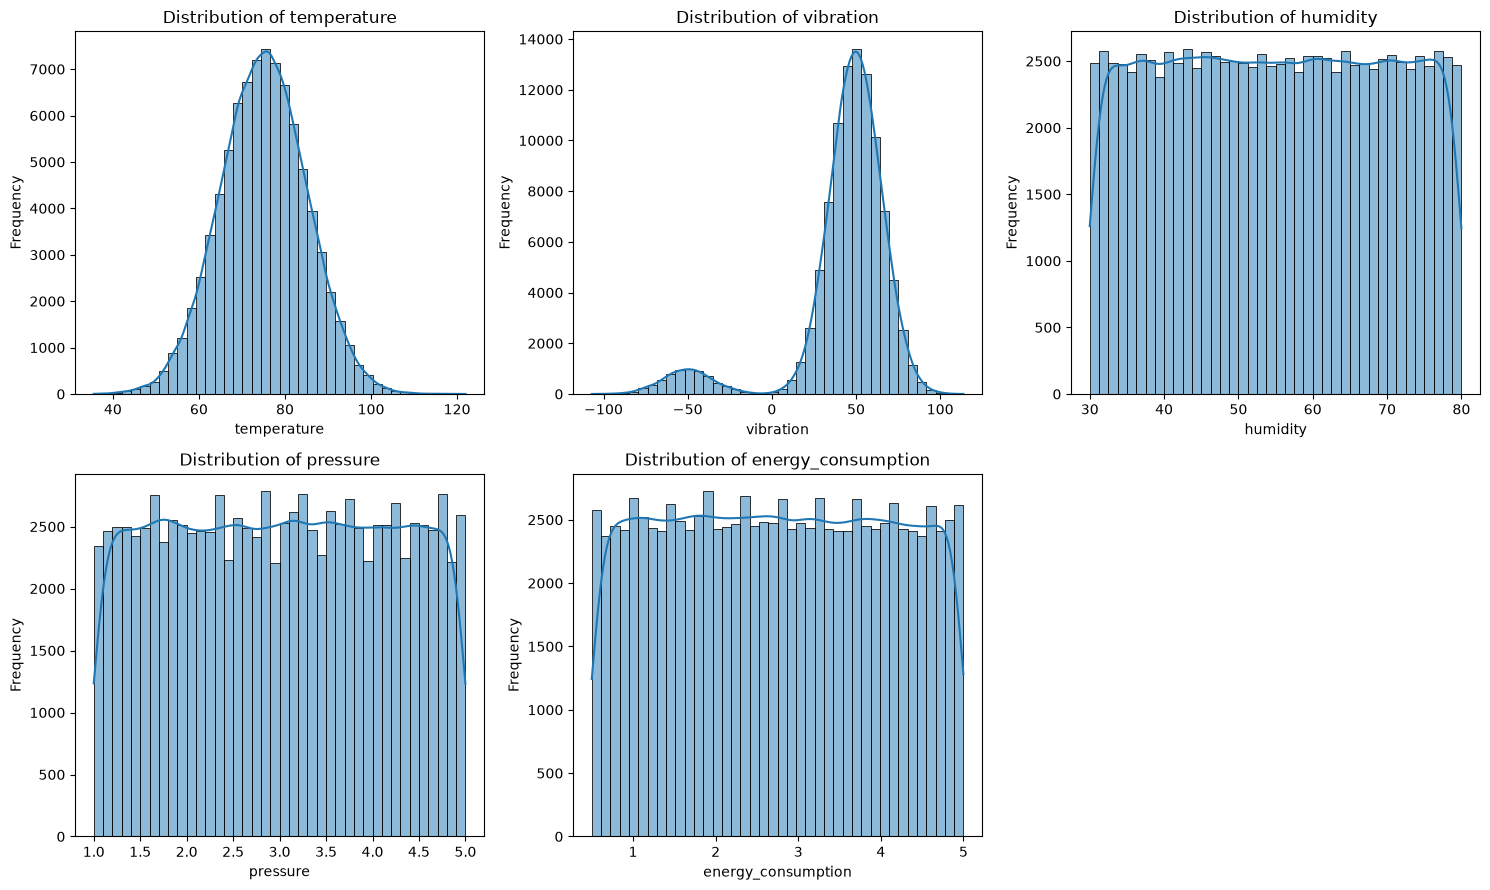

In [26]:
sensor_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, column in zip(axes.flat, sensor_columns):
    sns.histplot(
        data=df,
        x=column,
        bins=40,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_ylabel("Frequency")

# Hide unused subplot
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Sensor Distribution Analysis — Findings

Histograms were generated for all five sensor variables to examine their distributions and identify unusual patterns.

**Temperature:** The distribution is approximately normal, with most observations concentrated around 75°C.

**Vibration:** The distribution is bimodal, with a dominant peak around +50 mm/s and a smaller peak around -50 mm/s. This indicates two distinct groups of readings rather than isolated negative outliers. The underlying cause requires further investigation.

**Humidity:** Readings are approximately uniformly distributed between 30% and 80%.

**Pressure:** Readings are approximately uniformly distributed between 1 and 5 bar.

**Energy consumption:** Readings are approximately uniformly distributed between 0.5 and 5 kWh.

**Implications for preprocessing:**
The vibration distribution requires further investigation before negative readings are removed or transformed. No other sensor shows an obvious distribution-level data quality issue.
The predictive usefulness of these features cannot be established from their individual distributions alone. Further analysis will compare sensor readings against the maintenance target.

## 4. Sensor Relationships with Maintenance Requirements

### Objective:
To investigate whether sensor readings differ between machines
that require maintenance and those that do not.

### Method:
Compare the mean and median sensor readings for each
maintenance class.

### Importance:
This analysis helps identify which sensor variables may
contribute to predicting maintenance requirements.

In [27]:
sensor_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption"
]

# Compare sensor readings by maintenance class
sensor_comparison = df.groupby(
    "maintenance_required"
)[sensor_columns].agg(["mean", "median", "std"])

display(sensor_comparison.round(2))

temperature               vibration                \
                            mean median    std      mean median    std   
maintenance_required                                                     
0                          73.63  74.23   8.81     42.58  48.19  28.34   
1                          80.75  80.66  12.42     46.34  50.58  31.99   

                     humidity               pressure               \
                         mean median    std     mean median   std   
maintenance_required                                                
0                       55.02  55.01  14.42      3.0   3.01  1.15   
1                       54.88  54.85  14.50      3.0   2.99  1.15   

                     energy_consumption              
                                   mean median  std  
maintenance_required                                 
0                                  2.75   2.74  1.3  
1                                  2.75   2.75  1.3

### Sensor Relationships with Maintenance — Findings

The mean, median and standard deviation of five sensor readings were compared between observations requiring maintenance and those not requiring maintenance.

**Temperature:** Maintenance-required observations have a higher mean temperature (80.75°C) than non-maintenance observations (73.63°C), a difference of 7.12°C. This suggests temperature may be an important predictive feature.

**Vibration:** Maintenance-required observations have a higher mean vibration reading (46.34 mm/s) than non-maintenance observations (42.58 mm/s). However, the bimodal vibration distribution requires further investigation.

**Humidity, pressure and energy consumption:** These features show minimal differences in mean values between the two classes, suggesting limited discrimination based on their averages alone.

**Implications:** Temperature and vibration are promising candidates for further analysis. However, differences in averages do not establish predictive importance or prove that sensor changes occur before maintenance events. Further visualizations, correlation analysis and model evaluation are required.

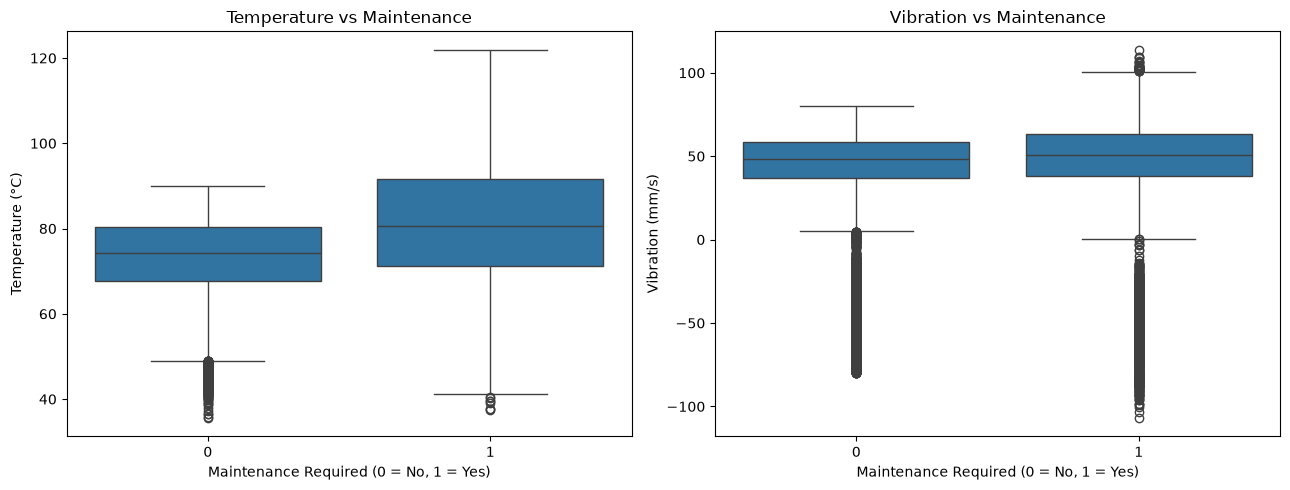

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df,
    x="maintenance_required",
    y="temperature",
    ax=axes[0]
)
axes[0].set_title("Temperature vs Maintenance")
axes[0].set_xlabel("Maintenance Required (0 = No, 1 = Yes)")
axes[0].set_ylabel("Temperature (°C)")

sns.boxplot(
    data=df,
    x="maintenance_required",
    y="vibration",
    ax=axes[1]
)
axes[1].set_title("Vibration vs Maintenance")
axes[1].set_xlabel("Maintenance Required (0 = No, 1 = Yes)")
axes[1].set_ylabel("Vibration (mm/s)")

plt.tight_layout()
plt.show()

### Temperature and Vibration Boxplot Analysis

Boxplots were generated to compare temperature and vibration distributions between maintenance-required and non-maintenance observations.

**Temperature:** Maintenance-required observations have a higher median temperature and greater variability. However, considerable overlap exists between the two classes, suggesting temperature alone may not be sufficient for reliable classification.

**Vibration:** The maintenance-required group has a slightly higher median vibration, but the distributions overlap substantially. Numerous negative readings appear below the lower whiskers, consistent with the previously identified secondary vibration cluster.

**Conclusion:** Temperature appears to provide stronger separation between maintenance classes than vibration. However, both features require further evaluation to determine their predictive usefulness.

## 5. Correlation Analysis

### Objective:
To investigate the strength and direction of linear relationships
between machine sensor readings and maintenance requirements.

### Method:
Calculate Pearson correlation coefficients and visualize
the results using a correlation heatmap.

### Importance:
Correlation analysis can help identify potentially useful
predictive features and relationships between sensors.

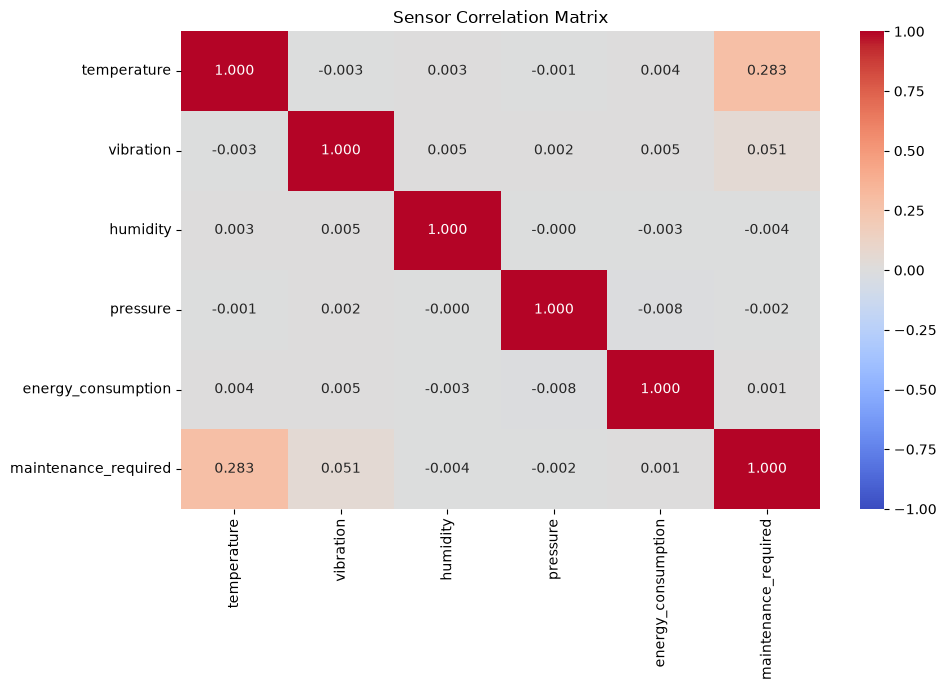

In [29]:
# Select numerical sensor features and target
correlation_columns = [
    "temperature",
    "vibration",
    "humidity",
    "pressure",
    "energy_consumption",
    "maintenance_required"
]

# Calculate Pearson correlations
correlation_matrix = df[correlation_columns].corr()

# Visualize correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Sensor Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation Analysis — Findings

Pearson correlation analysis was performed to investigate linear relationships between the five sensor variables and `maintenance_required`.

Temperature showed the strongest positive correlation with maintenance requirements (r = 0.283), suggesting that higher temperatures are associated with an increased likelihood of maintenance being required.

Vibration showed a very weak positive correlation (r = 0.051), while humidity (r = -0.004), pressure (r = -0.002) and energy consumption (r = 0.001) showed negligible linear correlations.

Correlations between the sensor variables were also close to zero, indicating limited linear multicollinearity.

**Implications:**

Temperature appears to be the most promising individual sensor feature based on linear correlation. However, its moderate-to-weak association suggests that temperature alone may not provide sufficient predictive performance.

The other sensors should not be automatically excluded because Pearson correlation does not capture nonlinear relationships or feature interactions.

Further analysis is needed to evaluate the contribution of derived variables and investigate whether sensor readings provide advance warning of maintenance requirements.

## 6. Derived Feature Analysis

### Objective:
To investigate the relationships between derived machine
status indicators and maintenance requirements.

### Method:
Examine the distributions and relationships of machine_status,
anomaly_flag, predicted_remaining_life, failure_type,
and downtime_risk.

### Importance:
These variables may provide additional information about
maintenance requirements. However, potential target leakage
must be investigated before including them in model training.

In [30]:
# Examine derived features

derived_categorical = [
    "machine_status",
    "anomaly_flag",
    "failure_type"
]

for column in derived_categorical:
    print(f"\n=== {column} ===")

    # Compare maintenance proportions within each category
    comparison = pd.crosstab(
        df[column],
        df["maintenance_required"],
        normalize="index"
    ) * 100

    display(comparison.round(2))


=== machine_status ===


maintenance_required,0,1
machine_status,,
0,89.08,10.92
1,89.31,10.69
2,0.00,100.00



=== anomaly_flag ===


maintenance_required,0,1
anomaly_flag,,
0,88.16,11.84
1,0.00,100.00



=== failure_type ===


maintenance_required,0,1
failure_type,,
Electrical Fault,0.00,100.00
Normal,87.38,12.62
Overheating,0.00,100.00
Pressure Drop,0.00,100.00
Vibration Issue,0.00,100.00


### Derived Categorical Features — Findings

Three derived categorical variables were analyzed against the `maintenance_required` target.

**Machine Status:** All observations with `machine_status = 2` (failure) require maintenance. Idle and running observations have maintenance-required rates of 10.92% and 10.69%, respectively.

**Anomaly Flag:** All observations with `anomaly_flag = 1` require maintenance, while 11.84% of observations without an anomaly flag also require maintenance.

**Failure Type:** All observations categorized as Electrical Fault, Overheating, Pressure Drop or Vibration Issue require maintenance. However, 12.62% of observations categorized as Normal also require maintenance.

**Implications:**

These derived features have strong relationships with the maintenance target. However, their use in predictive models requires careful consideration because they may contain information about existing failures or introduce target leakage.

For predictive maintenance, features should be available before the maintenance decision or failure event. The raw sensor readings will therefore be evaluated separately from potentially leakage-prone derived features.

In [31]:
derived_numerical = [
    "predicted_remaining_life",
    "downtime_risk"
]

# Compare derived numerical features by maintenance class
derived_comparison = df.groupby(
    "maintenance_required"
)[derived_numerical].agg(
    ["mean", "median", "std", "min", "max"]
)

display(derived_comparison.round(2))

predicted_remaining_life                          \
                                         mean median     std min  max   
maintenance_required                                                    
0                                      259.76  259.0  138.50  20  499   
1                                      130.34   42.0  150.59   1  499   

                     downtime_risk                        
                              mean median  std  min  max  
maintenance_required                                      
0                             0.00    0.0  0.0  0.0  0.0  
1                             0.45    0.0  0.5  0.0  1.0

In [32]:
# Calculate correlation with maintenance target
derived_correlations = df[
    [
        "predicted_remaining_life",
        "downtime_risk",
        "maintenance_required"
    ]
].corr()

display(derived_correlations.round(3))

,predicted_remaining_life,downtime_risk,maintenance_required
predicted_remaining_life,1.000,-0.436,-0.343
downtime_risk,-0.436,1.000,0.632
maintenance_required,-0.343,0.632,1.000


### Derived Numerical Features — Findings

The relationships between `predicted_remaining_life`, `downtime_risk` and `maintenance_required` were investigated using descriptive statistics and Pearson correlation.

**Predicted Remaining Life:** Observations requiring maintenance have a mean predicted remaining life of 130.34, compared with 259.76 for observations not requiring maintenance. The correlation with maintenance requirements is -0.343, indicating a moderate negative association.

**Downtime Risk:** The mean downtime risk is 0 for non-maintenance observations and 0.45 for maintenance-required observations. Its correlation with maintenance requirements is +0.632, representing a relatively strong positive association.

**Relationship Between Derived Features:** Predicted remaining life and downtime risk have a negative correlation of -0.436.

**Implications:**

Both derived features contain information strongly associated with maintenance requirements. However, their generation methods must be investigated to determine whether they introduce target leakage.

Initial predictive models should use raw sensor readings as a baseline. Derived features may be evaluated separately if they are confirmed to be available before the maintenance event and independent of the target label.

## 7. Chronological Machine Analysis

### Objective:
To investigate how sensor readings and maintenance requirements
change over time for individual machines.

### Method:
Convert timestamps to datetime format, sort observations
by machine and time, and examine the time intervals
between consecutive readings.

### Importance:
Predictive maintenance requires understanding whether sensor
readings provide advance warning of maintenance events.

In [33]:
# Create a separate dataframe to preserve the original data
df_time = df.copy()

# Convert timestamps into datetime
df_time["timestamp"] = pd.to_datetime(df_time["timestamp"])

# Sort observations by machine and timestamp
df_time = df_time.sort_values(
    ["machine_id", "timestamp"]
).reset_index(drop=True)

# Calculate time between consecutive readings per machine
df_time["time_gap_minutes"] = (
    df_time.groupby("machine_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

print("Earliest timestamp:", df_time["timestamp"].min())
print("Latest timestamp:", df_time["timestamp"].max())

print("\nTime gap statistics (minutes):")
display(df_time["time_gap_minutes"].describe())

print("\nReadings per machine:")
display(df_time.groupby("machine_id").size().describe())

Earliest timestamp: 2025-01-01 00:00:00
Latest timestamp: 2025-03-11 10:39:00

Time gap statistics (minutes):


count    99950.000000
mean        49.973307
std         49.273879
min          1.000000
25%         15.000000
50%         35.000000
75%         69.000000
max        514.000000
Name: time_gap_minutes, dtype: float64


Readings per machine:


count      50.000000
mean     2000.000000
std        51.673228
min      1906.000000
25%      1956.250000
50%      2002.500000
75%      2042.500000
max      2092.000000
dtype: float64

### Chronological Data Analysis — Findings

The dataset covers the period from 1 January 2025 to 11 March 2025 and contains 100,000 observations across 50 machines.

Each machine has approximately 2,000 observations on average.

The time intervals between consecutive readings for the same machine are irregular, with a median of 35 minutes, mean of 49.97 minutes and maximum of 514 minutes.

**Implications:**

Although the overall dataset contains regularly spaced timestamps, individual machines are not necessarily sampled at regular intervals.

This may limit the ability to detect short-term sensor changes preceding maintenance events.

Chronological analysis should therefore use actual timestamps rather than assuming fixed intervals between consecutive observations.

Further investigation is required to determine whether temperature and vibration readings change before maintenance events.

## 8. Maintenance Transition Analysis

### Objective:
To identify transitions from normal maintenance status
to maintenance-required status for individual machines.

### Method:
Compare each machine's current maintenance label with
its previous observation, ordered chronologically.

### Importance:
Identifying maintenance transitions helps determine
whether the dataset supports analysis of sensor behavior
before maintenance becomes necessary.

In [34]:
# Get previous maintenance status for each machine
df_time["previous_maintenance"] = (
    df_time.groupby("machine_id")["maintenance_required"]
    .shift(1)
)

# Identify transitions from 0 to 1
df_time["maintenance_start"] = (
    (df_time["previous_maintenance"] == 0) &
    (df_time["maintenance_required"] == 1)
)

# Count transitions
total_transitions = df_time["maintenance_start"].sum()

print("Total maintenance transitions (0 → 1):", total_transitions)

# Count transitions per machine
transitions_per_machine = (
    df_time.groupby("machine_id")["maintenance_start"]
    .sum()
)

print("\nTransitions per machine:")
display(transitions_per_machine.describe())

print("\nFirst 10 maintenance transitions:")
display(
    df_time.loc[
        df_time["maintenance_start"],
        ["timestamp", "machine_id", "maintenance_required"]
    ].head(10)
)

Total maintenance transitions (0 → 1): 15695

Transitions per machine:


count     50.000000
mean     313.900000
std       15.003741
min      285.000000
25%      302.750000
50%      313.000000
75%      325.500000
max      346.000000
Name: maintenance_start, dtype: float64


First 10 maintenance transitions:


,timestamp,machine_id,maintenance_required
5,2025-01-01 03:43:00,1,1
10,2025-01-01 07:47:00,1,1
13,2025-01-01 08:59:00,1,1
22,2025-01-01 15:07:00,1,1
26,2025-01-01 18:15:00,1,1
39,2025-01-02 07:29:00,1,1
43,2025-01-02 12:19:00,1,1
47,2025-01-02 14:04:00,1,1
51,2025-01-02 18:59:00,1,1
58,2025-01-03 01:03:00,1,1


### Maintenance Transition Analysis — Findings

Chronological analysis identified 15,695 transitions from `maintenance_required = 0` to `maintenance_required = 1` across 50 machines.

Each machine experienced an average of 313.9 observed transitions, with a minimum of 285 and maximum of 346.

The high frequency of transitions suggests that the maintenance label changes frequently within individual machine histories.

**Implications:**

These transitions should not automatically be interpreted as confirmed physical failures. They represent changes in the recorded maintenance requirement.

The frequent transitions may indicate that the dataset represents maintenance classifications or recommendations rather than realistic equipment breakdown and repair cycles.

Further analysis is required to determine whether sensor readings contain measurable warning signals before maintenance-required observations.

## 9. Pre-Maintenance Sensor Analysis

### Objective:
To investigate whether temperature and vibration readings
change before maintenance requirements are recorded.

### Method:
Compare sensor readings from the five preceding observations
with readings at the maintenance transition.

### Importance:
This analysis helps determine whether the dataset contains
potential early-warning signals for predictive maintenance.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use existing chronologically sorted dataframe
pre_maintenance = df_time.copy()

sensor_columns = ["temperature", "vibration"]
window_size = 5

results = []

# Group by machine once instead of repeatedly filtering
for machine_id, machine_data in pre_maintenance.groupby(
    "machine_id", sort=False
):

    # Preserve chronological order within each machine
    machine_data = machine_data.sort_values("timestamp")

    # Reset index for fast positional access
    machine_data = machine_data.reset_index(drop=True)

    # Find maintenance transitions for this machine
    transition_positions = np.flatnonzero(
        machine_data["maintenance_start"].to_numpy()
    )

    for pos in transition_positions:

        # Require 5 previous observations
        if pos < window_size:
            continue

        # Extract previous 5 readings + transition reading
        window = machine_data.iloc[
            pos - window_size : pos + 1
        ]

        # Previous 5 observations must all be normal
        if not (
            window["maintenance_required"].iloc[:-1] == 0
        ).all():
            continue

        # Collect readings
        for relative_pos, (_, row) in enumerate(
            window.iterrows()
        ):
            results.append({
                "relative_observation": relative_pos - window_size,
                "temperature": row["temperature"],
                "vibration": row["vibration"]
            })

pre_maintenance_results = pd.DataFrame(results)

# Calculate average readings
average_readings = pre_maintenance_results.groupby(
    "relative_observation"
)[sensor_columns].mean()

print(
    "Complete pre-maintenance windows:",
    len(pre_maintenance_results) // (window_size + 1)
)

display(average_readings.round(2))

Complete pre-maintenance windows: 6553


,temperature,vibration
relative_observation,,
-5,73.47,42.56
-4,73.52,42.73
-3,73.70,42.82
-2,73.71,42.47
-1,73.52,42.86
0,80.87,46.56


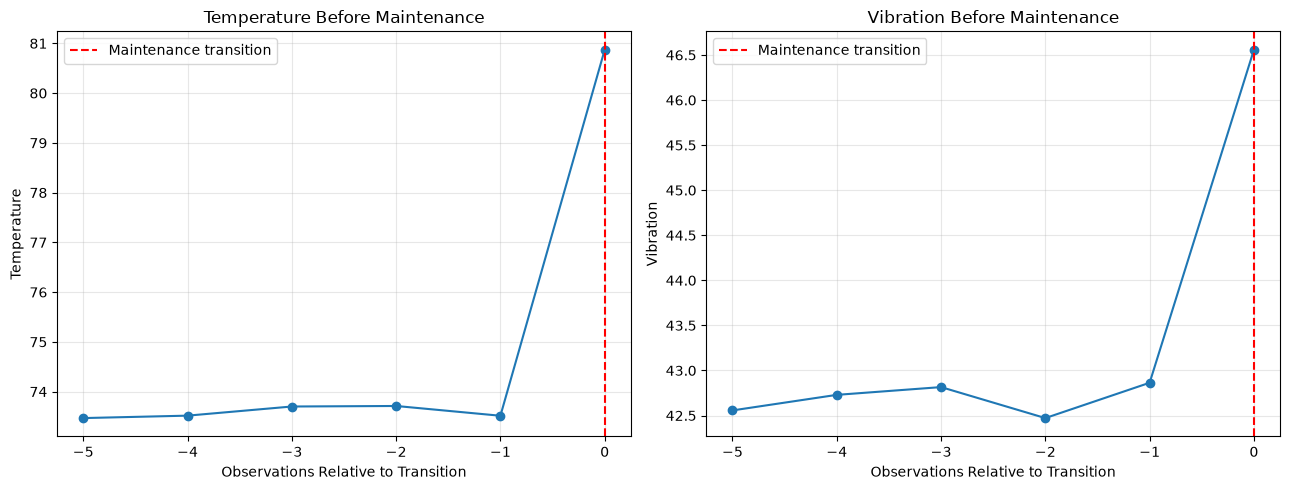

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, sensor in zip(axes, sensor_columns):
    ax.plot(
        average_readings.index,
        average_readings[sensor],
        marker="o"
    )

    ax.axvline(
        x=0,
        color="red",
        linestyle="--",
        label="Maintenance transition"
    )

    ax.set_title(f"{sensor.capitalize()} Before Maintenance")
    ax.set_xlabel("Observations Relative to Transition")
    ax.set_ylabel(sensor.capitalize())
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Pre-Maintenance Sensor Analysis — Findings

Temperature and vibration readings were analyzed across five observations preceding a transition from `maintenance_required = 0` to `maintenance_required = 1`.

**Temperature:** Average temperature remained relatively stable around 73.5–73.8°C across the five preceding observations, before increasing sharply to approximately 80.9°C at the maintenance transition.

**Vibration:** Average vibration remained around 42–43 mm/s before increasing to approximately 46.5 mm/s at the transition.

**Implications:**

The results do not show a clear gradual increase in temperature or vibration before maintenance becomes required.

This suggests that the sensor readings may be more useful for identifying current maintenance requirements than predicting them in advance.

However, the analysis is based on aggregated observations rather than fixed time intervals. Individual machine patterns and specific failure categories may differ.

Further investigation is required before concluding that the dataset contains no useful early-warning signals.

### Pre-Maintenance Window Analysis — Conclusion

Of the 15,695 observed maintenance transitions, 6,553 (41.75%) had five consecutive preceding observations where maintenance was not required.

Across these windows, average temperature remained between 73.47°C and 73.71°C before increasing to 80.87°C at the maintenance transition.

Average vibration remained between 42.47 and 42.86 before increasing to 46.56 at the transition.

**Key finding:** No consistent upward trend was observed in either sensor during the five preceding observations. The largest changes occurred at the maintenance transition itself.

**Implications:** The dataset appears more suitable for classifying current maintenance requirements than forecasting them several observations in advance. However, this conclusion is limited to the selected windows and their aggregated averages.

Further analysis of individual transitions, failure categories and actual time intervals may reveal patterns not visible in the aggregated results.

## 10. Failure Type Analysis

### Objective:
To investigate whether different failure categories are
associated with distinct temperature and vibration patterns.

### Method:
Compare failure-type frequencies and average sensor readings
for each category.

### Importance:
Different maintenance problems may have different sensor
signatures that are hidden when all events are combined.

In [37]:
# Count observations for each failure category
failure_counts = df["failure_type"].value_counts()

display(failure_counts)

# Compare average sensor readings by failure type
failure_sensor_summary = df.groupby(
    "failure_type"
)[["temperature", "vibration"]].agg(
    ["count", "mean", "median", "std"]
)

display(failure_sensor_summary.round(2))

failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64

temperature                      vibration                \
                       count   mean median    std     count   mean median   
failure_type                                                                
Electrical Fault         870  75.46  75.16   9.95      1014  42.13  47.54   
Normal                 79002  75.02  75.09  10.03     91899  43.34  48.64   
Overheating             1708  74.79  74.58  10.01      1989  43.43  48.79   
Pressure Drop           1723  75.30  75.04  10.26      1969  42.41  48.18   
Vibration Issue         2697  75.28  75.42  10.21      3129  43.77  48.84   

                         
                    std  
failure_type             
Electrical Fault  29.04  
Normal            29.13  
Overheating       28.64  
Pressure Drop     30.33  
Vibration Issue   28.85

### Failure Type Analysis — Findings

The dataset contains 91,899 Normal observations, 3,129 Vibration Issues, 1,989 Overheating cases, 1,969 Pressure Drops and 1,014 Electrical Faults.

The Normal category accounts for approximately 91.90% of observations, indicating substantial class imbalance in the failure-type distribution.

Temperature and vibration averages are similar across all five failure categories.

For example, Overheating observations have a mean temperature of 74.79°C compared with 75.00°C for Normal observations. Similarly, Vibration Issue observations have a mean vibration reading of 43.77 compared with 43.34 for Normal observations.

**Implications:**

The results do not reveal clear failure-specific differences in average temperature or vibration readings.

However, further investigation of the remaining sensors and their distributions is necessary before concluding that failure types cannot be distinguished.

The primary machine learning objective remains binary classification of `maintenance_required`.

## 11. Failure-Specific Sensor Analysis

### Objective:
To determine whether failure categories exhibit distinctive
patterns in their corresponding sensor measurements.

### Method:
Compare sensor distributions and extreme readings across
failure categories.

### Importance:
This analysis helps assess whether the recorded failure types
are supported by observable sensor measurements.

In [38]:
failure_sensor_mapping = {
    "Overheating": "temperature",
    "Vibration Issue": "vibration",
    "Pressure Drop": "pressure"
}

for failure_type, sensor in failure_sensor_mapping.items():

    normal = df.loc[
        df["failure_type"] == "Normal", sensor
    ].dropna()

    failure = df.loc[
        df["failure_type"] == failure_type, sensor
    ].dropna()

    print(f"\n=== {failure_type}: {sensor} ===")

    comparison = pd.DataFrame({
        "Normal": normal.describe(),
        failure_type: failure.describe()
    })

    display(comparison.round(2))


=== Overheating: temperature ===


,Normal,Overheating
count,79002.00,1708.00
mean,75.02,74.79
std,10.03,10.01
min,35.55,37.34
25%,68.27,68.60
50%,75.09,74.58
75%,81.75,81.61
max,121.94,110.19



=== Vibration Issue: vibration ===


,Normal,Vibration Issue
count,91899.00,3129.00
mean,43.34,43.77
std,29.13,28.85
min,-106.98,-88.21
25%,37.22,37.32
50%,48.64,48.84
75%,59.25,59.66
max,113.80,109.71



=== Pressure Drop: pressure ===


,Normal,Pressure Drop
count,91899.00,1969.00
mean,3.00,2.97
std,1.15,1.16
min,1.00,1.00
25%,2.00,1.96
50%,3.01,2.91
75%,4.00,3.99
max,5.00,5.00


### Failure-Specific Sensor Analysis — Findings

The distributions of temperature, vibration and pressure were compared between Normal observations and their corresponding failure categories.

**Overheating:** The mean temperature for Overheating observations was 74.79°C, compared with 75.02°C for Normal observations. The distributions showed similar central tendencies and variability, with no clear evidence of elevated temperatures in the Overheating category.

**Vibration Issue:** Mean vibration was 43.77 for Vibration Issue observations and 43.34 for Normal observations. The medians and standard deviations were also similar, indicating substantial overlap between the categories.

**Pressure Drop:** Mean pressure was 2.97 for Pressure Drop observations compared with 3.00 for Normal observations. The difference was small relative to the variability of the measurements.

**Implications:**

The corresponding sensor measurements do not exhibit strong differences between Normal and failure-specific observations.

This suggests that identifying individual failure types using these sensor readings may be challenging.

However, these descriptive statistics do not establish that the failure labels are incorrect or that classification is impossible. Further model evaluation would be necessary to assess predictive performance.

## 12. Machine-Level Maintenance Analysis

### Objective:
To investigate whether maintenance requirements differ
substantially between individual machines.

### Method:
Calculate the percentage of maintenance-required observations
for each machine.

### Importance:
Machine-level differences may affect model generalization
and the selection of an appropriate training/testing strategy.

In [39]:
# Calculate maintenance-required percentage for each machine
machine_maintenance = (
    df.groupby("machine_id")["maintenance_required"]
    .agg(["count", "sum", "mean"])
)

machine_maintenance["maintenance_percentage"] = (
    machine_maintenance["mean"] * 100
)

# Display summary statistics
print("Maintenance percentage across machines:")
display(machine_maintenance["maintenance_percentage"].describe())

# Display machines with highest maintenance percentages
print("\nTop 10 machines by maintenance percentage:")
display(
    machine_maintenance.sort_values(
        "maintenance_percentage",
        ascending=False
    ).head(10).round(2)
)

Maintenance percentage across machines:


count    50.000000
mean     19.696856
std       0.949449
min      17.287630
25%      19.058202
50%      19.589188
75%      20.378794
max      21.511018
Name: maintenance_percentage, dtype: float64


Top 10 machines by maintenance percentage:


,count,sum,mean,maintenance_percentage
machine_id,,,,
43,1906,410,0.22,21.51
50,1912,410,0.21,21.44
24,1984,418,0.21,21.07
32,2031,426,0.21,20.97
5,2043,428,0.21,20.95
29,2044,427,0.21,20.89
30,2074,433,0.21,20.88
6,1934,403,0.21,20.84
42,2019,417,0.21,20.65


### Machine-Level Maintenance Analysis — Findings

Maintenance-required rates were calculated for all 50 machines.

The average maintenance-required rate was 19.70%, with a standard deviation of 0.95 percentage points.

Individual machine rates ranged from 17.29% to 21.51%. Machine 43 had the highest observed rate (21.51%), followed by Machine 50 (21.44%).

The relatively narrow range suggests that maintenance requirements occur at broadly similar frequencies across machines.

**Implications:**

Machine identity alone may provide limited predictive information, although this must be verified through model evaluation.

A chronological train-test split is recommended for evaluating future maintenance classification on the existing machine population.

A machine-based split could be considered as an additional evaluation to assess generalization to previously unseen machines.

## 13. Final EDA Conclusions

### Key Findings

1. **Dataset Quality:** The dataset contains 100,000 observations across 50 machines. Temperature has 14% missing values, and no duplicate records were identified.

2. **Sensor Distributions:** Temperature is approximately normally distributed, while humidity, pressure and energy consumption are approximately uniformly distributed. The original vibration distribution was bimodal due to a suspected systematic sign inversion affecting 6,667 quarter-hour readings. After provisional correction, vibration became approximately normally distributed.

3. **Sensor Correlations:** Temperature has the strongest Pearson correlation with maintenance requirements (r = 0.283). Correcting the suspected vibration sign inversion increased its correlation from 0.0513 to 0.1131. The remaining sensors showed negligible linear correlations.

4. **Maintenance Target Rule:** A rule involving `machine_status == 2`, `anomaly_flag == 1`, or `predicted_remaining_life < 20` reproduced all 100,000 maintenance labels with 100% agreement. This indicates a significant risk of target leakage if these derived features are used for model training.

5. **Anomaly Threshold Investigation:** Temperature and vibration thresholds of approximately 90°C and 80 were strongly associated with anomaly flags. The exclusive threshold rule achieved 99.073% agreement. Thirteen boundary observations had differing anomaly labels, while 922 unexplained anomalies involved missing temperature values. Rounding or unavailable original sensor values may explain these inconsistencies.

6. **Chronological Analysis:** A total of 15,695 maintenance transitions were identified. Analysis of 6,553 complete pre-maintenance windows found relatively stable temperature and vibration readings before a sharp increase at the maintenance transition. No clear gradual early-warning pattern was observed in the aggregated readings.

7. **Failure-Specific Analysis:** Overheating, Vibration Issue and Pressure Drop observations did not exhibit strong differences in their corresponding sensor measurements compared with Normal observations.

8. **Machine-Level Analysis:** Maintenance-required rates were relatively consistent across the 50 machines, ranging from 17.29% to 21.51%.

### Overall Conclusion

The EDA identified temperature as the strongest raw sensor feature associated with maintenance requirements, followed by corrected vibration.

The analysis also revealed systematic data-quality issues and strong relationships between derived features and the maintenance target.

Although the dataset supports classification of current maintenance requirements, the examined pre-maintenance sensor patterns did not demonstrate clear advance-warning signals.

Consequently, the project will focus primarily on classifying maintenance requirements using sensor measurements, while acknowledging the limitations of predicting failures before they occur.

### Recommendations for Model Development

- Use `maintenance_required` as the binary classification target.
- Use raw sensor measurements as the primary model features.
- Exclude potentially leakage-prone features such as `machine_status`, `anomaly_flag`, `predicted_remaining_life`, `failure_type` and `downtime_risk`.
- Handle missing temperature values through training-only preprocessing.
- Apply the documented vibration sign correction provisionally and compare performance against uncorrected data.
- Preserve chronological order when splitting training and testing data.
- Train and evaluate at least three classification models.
- Compare precision, recall, F1-score and PR-AUC rather than relying on accuracy alone.
- Document the limitations of the dataset and the distinction between current maintenance classification and advance failure prediction.